# Segment the Data: K-Means, DBSCAN and PCA

**Problem statement:** Scale the features, then apply K-Means (use the elbow
method to pick k) and DBSCAN to the same data, and compare the groupings they
produce. Use PCA to reduce the data to 2 dimensions and visualize the clusters
from both algorithms on a scatter plot.

**Dataset:** [Mall Customer Segmentation Data, Vijay Choudhary (Kaggle)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).

**Submission by:** Bhanupriyacn. This notebook runs from top to bottom and retains
its executed tables and figures.

## 1. Method and feature choices

We segment customers using **Age**, **Annual Income (k$)** and **Spending Score
(1–100)**. CustomerID is an identifier and must not influence distances. Gender
is categorical; this experiment deliberately uses the three continuous numeric
features rather than assigning an arbitrary numeric distance to gender. Gender
remains in the exported customer table.

1. Inspect and clean the data, then standardize the numeric features.
2. Plot K-Means inertia for k = 1 through 10 and choose the elbow.
3. Apply DBSCAN to the **same standardized matrix**, with explicit parameters
   and a sensitivity analysis.
4. Fit one PCA transformation to that matrix and use its first two components
   for both scatter plots. Clustering takes place in all three standardized
   dimensions; PCA is used for visualization.
5. Compare coverage, cluster sizes, silhouette scores and label agreement.

This is exploratory unsupervised analysis: there are no ground-truth segment
labels, so classification accuracy and a train/test split are not applicable.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import io
import json
import platform
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
pd.set_option("display.max_columns", 12)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | numpy {np.__version__}")

Python 3.12.14 | pandas 3.0.6 | scikit-learn 1.9.1 | numpy 2.5.4


## 2. Load and inspect the dataset

On Kaggle, attach the linked dataset; the loader searches `/kaggle/input`.
Locally it checks `data/customer_segmentation/Mall_Customers.csv`,
`data/Mall_Customers.csv`, and `Mall_Customers.csv` next to the notebook or in its
parent folder. If needed, it downloads the public dataset archive from Kaggle
(internet required). No credentials are embedded in this notebook.

In [2]:
cwd = Path.cwd()
candidates = []
if Path("/kaggle/input").exists():
    candidates.extend(sorted(Path("/kaggle/input").rglob("Mall_Customers.csv")))
for base in (cwd, cwd.parent):
    candidates.extend([
        base / "data" / "customer_segmentation" / "Mall_Customers.csv",
        base / "data" / "Mall_Customers.csv",
        base / "Mall_Customers.csv",
    ])
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    dataset_url = ("https://www.kaggle.com/api/v1/datasets/download/"
                   "vjchoudhary7/customer-segmentation-tutorial-in-python")
    try:
        with urlopen(dataset_url, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(io.BytesIO(archive_bytes)) as archive:
            member = next(name for name in archive.namelist()
                          if Path(name).name == "Mall_Customers.csv")
            destination = cwd / "data" / "customer_segmentation"
            destination.mkdir(parents=True, exist_ok=True)
            data_path = destination / "Mall_Customers.csv"
            data_path.write_bytes(archive.read(member))
    except Exception as exc:
        raise RuntimeError(
            "Attach the Mall Customer Segmentation dataset on Kaggle, or place "
            "Mall_Customers.csv in a local data/customer_segmentation folder."
        ) from exc

df = pd.read_csv(data_path)
df.columns = df.columns.str.strip()
features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
required_columns = ["CustomerID", "Gender", *features]
assert set(required_columns).issubset(df.columns), "Unexpected dataset schema"
print(f"Loaded {data_path.name}: {df.shape[0]} customers, {df.shape[1]} columns")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str),
                      "missing_values": df.isna().sum()}))
print("Exact duplicate rows:", df.duplicated().sum())
display(df[features].describe().round(2))

Loaded Mall_Customers.csv: 200 customers, 5 columns


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,dtype,missing_values
CustomerID,int64,0
Gender,str,0
Age,int64,0
Annual Income (k$),int64,0
Spending Score (1-100),int64,0


Exact duplicate rows: 0


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


In [3]:
# Remove only identical records; customers with similar features remain distinct.
clean_df = df.drop_duplicates().reset_index(drop=True).copy()
assert clean_df["CustomerID"].is_unique, "Customer IDs must be unique"
X = clean_df[features].apply(pd.to_numeric, errors="raise")
assert not np.isinf(X.to_numpy(dtype=float)).any(), "Infinite feature value"
assert not X.isna().all().any(), "An entire feature is missing"

# Median imputation is a safeguard; this particular dataset has no missing values.
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
assert X_scaled.shape == (len(clean_df), len(features))
assert np.isfinite(X_scaled).all()
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-10)
display(pd.DataFrame({"feature": features,
                      "scaled_mean": X_scaled.mean(axis=0),
                      "scaled_std": X_scaled.std(axis=0)}).round(6))

,feature,scaled_mean,scaled_std
0,Age,-0.0,1.0
1,Annual Income (k$),-0.0,1.0
2,Spending Score (1-100),-0.0,1.0


**Why scale?** Both algorithms use Euclidean distances. StandardScaler gives each
numeric feature mean zero and population standard deviation one, so its original
units and spread do not automatically dominate the clustering. No identifiers,
cluster labels, or PCA coordinates enter the input matrix.

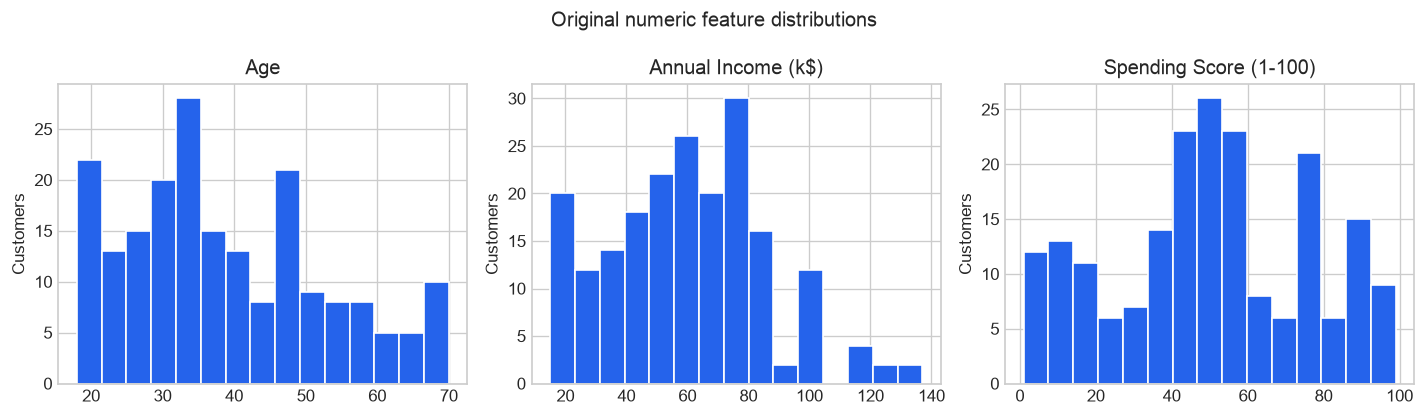

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, feature in zip(axes, features):
    ax.hist(X[feature].dropna(), bins=15, color="#2563eb", edgecolor="white")
    ax.set_title(feature)
    ax.set_ylabel("Customers")
fig.suptitle("Original numeric feature distributions")
fig.tight_layout()
plt.show()

## 3. K-Means: select k using the elbow method

Inertia is the sum of squared distances from customers to their assigned
centroids. It always decreases as k increases. We look for the bend after which
extra clusters deliver smaller improvements.

To make the elbow choice reproducible, normalize k and inertia to [0, 1] and
select the point with the greatest perpendicular distance below the straight
line joining the curve's endpoints. For that normalized descending curve,
maximizing `1 - normalized_k - normalized_inertia` gives the same choice. This
geometric heuristic supports visual inspection; it is not proof that there is a
single true number of customer groups. The tested k range can affect it.

,k,inertia,normalized_elbow_distance
0,1,600.0000,0.0000
1,2,389.3862,0.2955
2,3,295.2122,0.3662
3,4,205.2251,0.4288
4,5,168.2476,0.3890
5,6,133.8683,0.3443
6,7,117.0116,0.2657
7,8,103.8286,0.1801
8,9,92.3495,0.0911
9,10,81.9871,0.0000


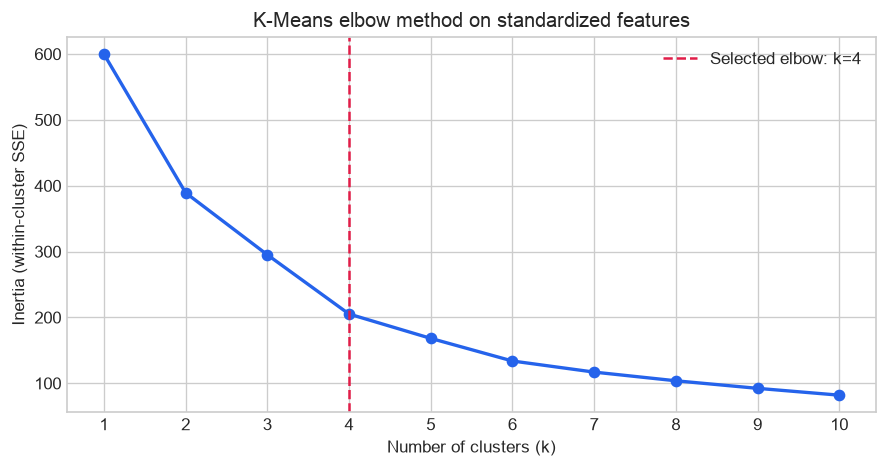

Selected k from the elbow curve: 4


In [5]:
k_values = np.arange(1, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=int(k), init="k-means++", n_init=20,
                   random_state=RANDOM_STATE)
    model.fit(X_scaled)
    inertias.append(model.inertia_)
inertias = np.asarray(inertias)
normalized_k = (k_values - k_values.min()) / (k_values.max() - k_values.min())
normalized_inertia = ((inertias - inertias.min()) /
                      (inertias.max() - inertias.min()))
elbow_distance = 1 - normalized_k - normalized_inertia
best_k = int(k_values[np.argmax(elbow_distance)])
elbow_table = pd.DataFrame({"k": k_values, "inertia": inertias,
                            "normalized_elbow_distance": elbow_distance})
display(elbow_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(k_values, inertias, "o-", color="#2563eb", linewidth=2)
ax.axvline(best_k, color="#e11d48", linestyle="--", label=f"Selected elbow: k={best_k}")
ax.set(xlabel="Number of clusters (k)", ylabel="Inertia (within-cluster SSE)",
       title="K-Means elbow method on standardized features", xticks=k_values)
ax.legend()
fig.tight_layout()
plt.show()
print(f"Selected k from the elbow curve: {best_k}")

In [6]:
kmeans = KMeans(n_clusters=best_k, init="k-means++", n_init=20,
                random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
print(f"K-Means: {best_k} clusters; silhouette = {kmeans_silhouette:.4f}")
display(pd.Series(kmeans_labels, name="cluster").value_counts()
        .sort_index().rename("customers").to_frame())

K-Means: 4 clusters; silhouette = 0.4040


,customers
cluster,
0,65
1,40
2,57
3,38


## 4. DBSCAN: density groups and noise

DBSCAN does not require k. `eps` is a neighborhood radius in standardized feature
space, and `min_samples` is the number of samples needed to make a core point
(including the point itself). A label of **-1** means noise, not an additional
customer segment.

We use **min_samples = 5** and inspect sorted distances to the fifth nearest
neighbor, counting the point itself, plus a small radius sensitivity table.
**eps = 0.50** is an exploratory choice near the median of these distances; it
retains distinct dense groups before larger radii start joining them. It is not
claimed to be a uniquely optimal radius or a sharp knee. We explicitly report
the tradeoff: small radii reject many customers, and large radii merge groups.

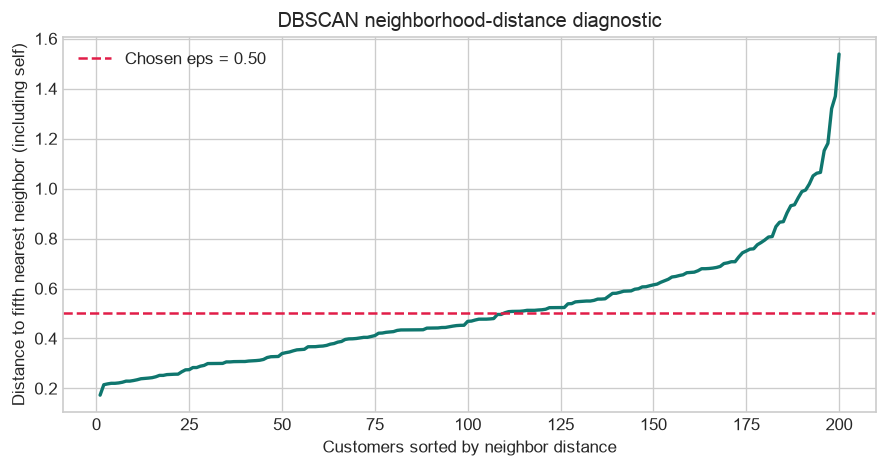

Median fifth-neighbor distance: 0.469


,eps,clusters_excluding_noise,noise_customers,coverage_pct,silhouette_assigned_only
0,0.40,6,98,51.0,0.5190
1,0.45,5,75,62.5,0.5423
2,0.50,6,60,70.0,0.4817
3,0.55,4,39,80.5,0.2336
4,0.60,2,28,86.0,0.2730
5,0.65,2,21,89.5,0.2646
6,0.70,1,14,93.0,NaN
7,0.80,1,6,97.0,NaN


In [7]:
MIN_SAMPLES = 5
EPS = 0.50
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
# Supplying X explicitly includes each observation itself (distance zero).
distances, _ = neighbors.kneighbors(X_scaled)
neighbor_distances = np.sort(distances[:, -1])
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.arange(1, len(neighbor_distances) + 1), neighbor_distances,
        color="#0f766e", linewidth=2)
ax.axhline(EPS, color="#e11d48", linestyle="--", label=f"Chosen eps = {EPS:.2f}")
ax.set(xlabel="Customers sorted by neighbor distance",
       ylabel="Distance to fifth nearest neighbor (including self)",
       title="DBSCAN neighborhood-distance diagnostic")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Median fifth-neighbor distance: {np.median(neighbor_distances):.3f}")

def safe_silhouette(matrix, labels):
    unique_labels = np.unique(labels)
    if len(labels) < 3 or not (2 <= len(unique_labels) < len(labels)):
        return np.nan
    return float(silhouette_score(matrix, labels))

sensitivity_rows = []
for radius in [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.80]:
    labels = DBSCAN(eps=radius, min_samples=MIN_SAMPLES).fit_predict(X_scaled)
    assigned = labels != -1
    sensitivity_rows.append({
        "eps": radius,
        "clusters_excluding_noise": len(np.unique(labels[assigned])),
        "noise_customers": int((~assigned).sum()),
        "coverage_pct": 100 * assigned.mean(),
        "silhouette_assigned_only": safe_silhouette(X_scaled[assigned], labels[assigned]),
    })
dbscan_sensitivity = pd.DataFrame(sensitivity_rows)
display(dbscan_sensitivity.round(4))

In [8]:
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, metric="euclidean")
dbscan_labels = dbscan.fit_predict(X_scaled)
assigned_mask = dbscan_labels != -1
dbscan_cluster_count = len(np.unique(dbscan_labels[assigned_mask]))
noise_count = int((~assigned_mask).sum())
dbscan_silhouette = safe_silhouette(X_scaled[assigned_mask], dbscan_labels[assigned_mask])
print(f"DBSCAN: {dbscan_cluster_count} clusters, {noise_count} noise customers "
      f"({100 * (~assigned_mask).mean():.1f}%), eps={EPS}, min_samples={MIN_SAMPLES}")
display(pd.Series(dbscan_labels, name="cluster (-1 = noise)").value_counts()
        .sort_index().rename("customers").to_frame())

DBSCAN: 6 clusters, 60 noise customers (30.0%), eps=0.5, min_samples=5


,customers
cluster (-1 = noise),
-1,60
0,17
1,5
2,51
3,28
4,32
5,7


## 5. PCA to two dimensions and cluster scatter plots

Fit PCA **once** to the same standardized three-feature matrix. Both panels
use identical customer coordinates, axes and limits, so any grouping difference
comes from the algorithms. Centroids are projected with that same PCA model.
Cluster numbers and colors identify groups within each algorithm; equal colors
across panels do not imply equivalent membership.

The two-component explained variance quantifies how much information the plot
retains. Overlap in this projection does not necessarily mean overlap in the
three-dimensional space where clustering was fitted.

,component,explained_variance_pct
0,PC1,44.27
1,PC2,33.31


Total variance retained by 2D PCA: 77.57%


,PC1 loading,PC2 loading
Age,0.7064,0.0301
Annual Income (k$),-0.0480,0.9988
Spending Score (1-100),-0.7062,-0.0378


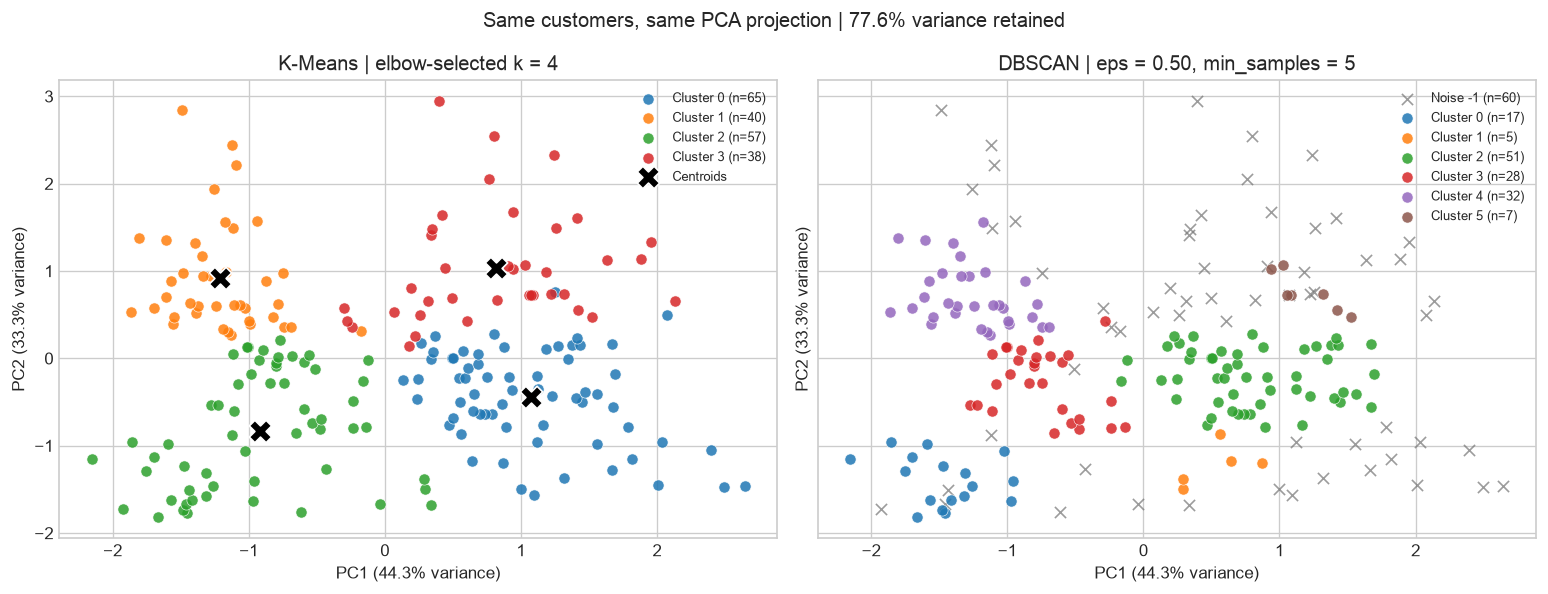

In [9]:
pca = PCA(n_components=2, svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_
centroids_pca = pca.transform(kmeans.cluster_centers_)
display(pd.DataFrame({"component": ["PC1", "PC2"],
                      "explained_variance_pct": 100 * explained_variance}).round(2))
print(f"Total variance retained by 2D PCA: {100 * explained_variance.sum():.2f}%")
display(pd.DataFrame(pca.components_.T, index=features,
                     columns=["PC1 loading", "PC2 loading"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
colors = plt.get_cmap("tab10").colors
for label in np.unique(kmeans_labels):
    mask = kmeans_labels == label
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=45, alpha=0.85,
                    color=colors[int(label) % len(colors)], edgecolors="white",
                    linewidths=0.4, label=f"Cluster {label} (n={mask.sum()})")
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], marker="X", s=180,
                color="black", edgecolors="white", linewidths=1, label="Centroids")
axes[0].set_title(f"K-Means | elbow-selected k = {best_k}")
for label in np.unique(dbscan_labels):
    mask = dbscan_labels == label
    if label == -1:
        axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=45, marker="x",
                        color="#737373", alpha=0.70, linewidths=1,
                        label=f"Noise -1 (n={mask.sum()})")
    else:
        axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=45, alpha=0.85,
                        color=colors[int(label) % len(colors)], edgecolors="white",
                        linewidths=0.4, label=f"Cluster {label} (n={mask.sum()})")
axes[1].set_title(f"DBSCAN | eps = {EPS:.2f}, min_samples = {MIN_SAMPLES}")
for ax in axes:
    ax.set_xlabel(f"PC1 ({100 * explained_variance[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({100 * explained_variance[1]:.1f}% variance)")
    ax.legend(fontsize=8, loc="best", framealpha=0.9)
fig.suptitle(f"Same customers, same PCA projection | {100 * explained_variance.sum():.1f}% variance retained")
fig.tight_layout()
artifact_dir = (Path("/kaggle/working/customer_segmentation_outputs")
                if Path("/kaggle/working").exists()
                else Path.cwd().parent / "outputs" / "customer_segmentation_results")
artifact_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(artifact_dir / "pca_cluster_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Compare the groupings

Silhouette ranges from -1 to 1; larger values indicate more separated, compact
groups for the evaluated observations. DBSCAN's noise is excluded from its
silhouette score. Because that score uses fewer customers, also compute the
K-Means silhouette **on the same DBSCAN-retained subset**. A larger DBSCAN score
alone does not establish a better segmentation for all customers.

Adjusted Rand Index (ARI) compares pairwise membership and is independent of
cluster-number permutations. The primary ARI below excludes noise; the all-row
ARI is supplementary and treats all noise points as one artificial group.
Neither measure is accuracy against true customer classes.

In [10]:
kmeans_subset_silhouette = safe_silhouette(X_scaled[assigned_mask], kmeans_labels[assigned_mask])
comparison = pd.DataFrame([
    {"algorithm": "K-Means (all customers)", "clusters": best_k,
     "evaluated_customers": len(clean_df), "noise_customers": 0,
     "coverage_pct": 100.0, "silhouette": kmeans_silhouette},
    {"algorithm": "K-Means (DBSCAN-retained subset)",
     "clusters": len(np.unique(kmeans_labels[assigned_mask])),
     "evaluated_customers": int(assigned_mask.sum()), "noise_customers": np.nan,
     "coverage_pct": 100 * assigned_mask.mean(), "silhouette": kmeans_subset_silhouette},
    {"algorithm": "DBSCAN (noise excluded)", "clusters": dbscan_cluster_count,
     "evaluated_customers": int(assigned_mask.sum()), "noise_customers": noise_count,
     "coverage_pct": 100 * assigned_mask.mean(), "silhouette": dbscan_silhouette},
])
display(comparison.round(4))
ari_assigned = (float(adjusted_rand_score(kmeans_labels[assigned_mask], dbscan_labels[assigned_mask]))
                if assigned_mask.any() else np.nan)
ari_all = float(adjusted_rand_score(kmeans_labels, dbscan_labels))
print(f"ARI on DBSCAN-retained customers: {ari_assigned:.4f}")
print(f"ARI on all customers (noise treated as one group): {ari_all:.4f}")

membership = pd.crosstab(pd.Series(kmeans_labels, name="K-Means cluster"),
                         pd.Series(dbscan_labels, name="DBSCAN cluster (-1 = noise)"))
display(membership)

,algorithm,clusters,evaluated_customers,noise_customers,coverage_pct,silhouette
0,K-Means (all customers),4,200,0.0,100.0,0.4040
1,K-Means (DBSCAN-retained subset),4,140,NaN,70.0,0.4555
2,DBSCAN (noise excluded),6,140,60.0,70.0,0.4817


ARI on DBSCAN-retained customers: 0.7318
ARI on all customers (noise treated as one group): 0.4431


DBSCAN cluster (-1 = noise),-1,0,1,2,3,4,5
K-Means cluster,,,,,,,
0,15,0,3,47,0,0,0
1,8,0,0,0,0,32,0
2,9,17,2,2,27,0,0
3,28,0,0,2,1,0,7


In [11]:
results = clean_df.copy()
results["KMeans_Cluster"] = kmeans_labels
results["DBSCAN_Cluster"] = dbscan_labels
results["DBSCAN_Is_Noise"] = ~assigned_mask
results["PC1"] = X_pca[:, 0]
results["PC2"] = X_pca[:, 1]

def cluster_profile(label_column):
    profile = results.groupby(label_column)[features].mean().round(2)
    profile.insert(0, "customers", results.groupby(label_column).size())
    return profile

kmeans_profile = cluster_profile("KMeans_Cluster")
dbscan_profile = cluster_profile("DBSCAN_Cluster")
display(Markdown("**K-Means segment profiles (original feature units)**"))
display(kmeans_profile)
display(Markdown("**DBSCAN profiles (row -1 describes noise, not a segment)**"))
display(dbscan_profile)

**K-Means segment profiles (original feature units)**

,customers,Age,Annual Income (k$),Spending Score (1-100)
KMeans_Cluster,,,,
0,65,53.98,47.71,39.97
1,40,32.88,86.10,81.53
2,57,25.44,40.00,60.30
3,38,39.37,86.50,19.58


**DBSCAN profiles (row -1 describes noise, not a segment)**

,customers,Age,Annual Income (k$),Spending Score (1-100)
DBSCAN_Cluster,,,,
-1,60,40.13,68.53,31.53
0,17,23.76,25.82,78.18
1,5,38.20,27.80,31.80
2,51,53.67,54.16,48.41
3,28,24.11,54.32,50.46
4,32,32.75,80.88,83.62
5,7,43.86,78.71,14.57


In [12]:
high_spending_cluster = int(kmeans_profile["Spending Score (1-100)"].idxmax())
summary = {
    "dataset": "vjchoudhary7/customer-segmentation-tutorial-in-python",
    "customers": int(len(clean_df)), "features": features,
    "kmeans_k": best_k,
    "kmeans_silhouette_all": float(kmeans_silhouette),
    "kmeans_silhouette_dbscan_subset": float(kmeans_subset_silhouette),
    "dbscan_eps": EPS, "dbscan_min_samples": MIN_SAMPLES,
    "dbscan_clusters": int(dbscan_cluster_count),
    "dbscan_noise_customers": noise_count,
    "dbscan_coverage_pct": float(100 * assigned_mask.mean()),
    "dbscan_silhouette_assigned": float(dbscan_silhouette),
    "ari_assigned": float(ari_assigned), "ari_all": float(ari_all),
    "pca_variance_retained_pct": float(100 * explained_variance.sum()),
}
display(Markdown(f"""
## 7. Findings and conclusion

- **K-Means:** the elbow heuristic selects **k = {best_k}**. All **{len(clean_df)}**
  customers receive a segment; the full-data silhouette is **{kmeans_silhouette:.4f}**.
- **DBSCAN:** `eps={EPS:.2f}` and `min_samples={MIN_SAMPLES}` identify
  **{dbscan_cluster_count}** dense groups and **{noise_count} noise customers**
  (**{100 * (~assigned_mask).mean():.1f}%**). Its non-noise silhouette is
  **{dbscan_silhouette:.4f}**, compared with **{kmeans_subset_silhouette:.4f}** for
  K-Means evaluated on that identical retained subset.
- **Agreement:** ARI on retained customers is **{ari_assigned:.4f}**. The membership
  table shows how DBSCAN groups split or combine K-Means segments; their cluster
  IDs are arbitrary and need not match.
- **PCA:** two components retain **{100 * explained_variance.sum():.2f}%** of the
  standardized-feature variance. Both scatter plots use the same projection;
  some separation can be lost when the third dimension is omitted.
- **Interpretation:** K-Means cluster **{high_spending_cluster}** has the highest
  average spending score (**{kmeans_profile.loc[high_spending_cluster, 'Spending Score (1-100)']:.2f}**).
  The profile tables connect each algorithm's groups to original age, income
  and spending values instead of interpreting PCA coordinates as original units.
- **Practical choice:** for a complete segmentation of this small dataset,
  K-Means provides broader coverage. DBSCAN provides a complementary view of
  dense customer groups and sparse observations, but its many unassigned
  customers and radius sensitivity limit its use as the only segmentation.

These findings describe this learning dataset and the stated feature choices.
There are no true segment labels, the elbow is a heuristic, and DBSCAN noise
does not prove that a customer is anomalous or unimportant. Adding encoded
categorical features or changing scaling and density settings can change the
groups. Validate any marketing interpretation before applying it to real customers.
"""))

results.to_csv(artifact_dir / "customer_cluster_assignments.csv", index=False)
comparison.to_csv(artifact_dir / "clustering_comparison.csv", index=False)
dbscan_sensitivity.to_csv(artifact_dir / "dbscan_sensitivity.csv", index=False)
elbow_table.to_csv(artifact_dir / "kmeans_elbow.csv", index=False)
kmeans_profile.to_csv(artifact_dir / "kmeans_cluster_profiles.csv")
dbscan_profile.to_csv(artifact_dir / "dbscan_cluster_profiles.csv")
(artifact_dir / "results_summary.json").write_text(json.dumps(summary, indent=2))
print("Exported cluster assignments, metrics, sensitivity, profiles, summary and PCA figure.")


## 7. Findings and conclusion

- **K-Means:** the elbow heuristic selects **k = 4**. All **200**
  customers receive a segment; the full-data silhouette is **0.4040**.
- **DBSCAN:** `eps=0.50` and `min_samples=5` identify
  **6** dense groups and **60 noise customers**
  (**30.0%**). Its non-noise silhouette is
  **0.4817**, compared with **0.4555** for
  K-Means evaluated on that identical retained subset.
- **Agreement:** ARI on retained customers is **0.7318**. The membership
  table shows how DBSCAN groups split or combine K-Means segments; their cluster
  IDs are arbitrary and need not match.
- **PCA:** two components retain **77.57%** of the
  standardized-feature variance. Both scatter plots use the same projection;
  some separation can be lost when the third dimension is omitted.
- **Interpretation:** K-Means cluster **1** has the highest
  average spending score (**81.53**).
  The profile tables connect each algorithm's groups to original age, income
  and spending values instead of interpreting PCA coordinates as original units.
- **Practical choice:** for a complete segmentation of this small dataset,
  K-Means provides broader coverage. DBSCAN provides a complementary view of
  dense customer groups and sparse observations, but its many unassigned
  customers and radius sensitivity limit its use as the only segmentation.

These findings describe this learning dataset and the stated feature choices.
There are no true segment labels, the elbow is a heuristic, and DBSCAN noise
does not prove that a customer is anomalous or unimportant. Adding encoded
categorical features or changing scaling and density settings can change the
groups. Validate any marketing interpretation before applying it to real customers.


Exported cluster assignments, metrics, sensitivity, profiles, summary and PCA figure.


## References

- [Original dataset and data card (Vijay Choudhary, Kaggle)](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).
- [StandardScaler documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [K-Means documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- [DBSCAN documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html).
- [PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- [Silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
  and [Adjusted Rand Index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).